## ***Warning! Make a copy of the notebook before you start***

## Lab 3 - Ablations, Hyperparameter Tuning Methods, Normalizations

**Goal**: Learn a skill of making Ablations, Hyperparameter and Turning your Deep learning model to get the best performance.

**Usage**: Useful in Homeworks P2

**Lab workflow**:
- Go to **[Piazza post @238](https://piazza.com/class/mjnqcfnm4ci4v1/post/238)**, download the notebook and data. You can save it on Google Drive or local machine.
- Follow the instruction in this notebook and complete **13 checkpoints**.
- By the end of the Lab, respond in **[Piazza post @238](https://piazza.com/class/mjnqcfnm4ci4v1/post/238)** how many checkpoints you completed. It's not graded and designed to help you with your HWs.

**Prepared by**:
- Madhavi Gulavani, IDL TA S26, mgulavan@andrew.cmu.edu
- Manigandan Ramadasan, IDL TA S26, mramadas@andrew.cmu.edu

**Extra resources**: This Lab builds upon Recitation 0.11: Data preprocessing and 0.4 PyTorch


### How do we obtain the best performance from our DL model?

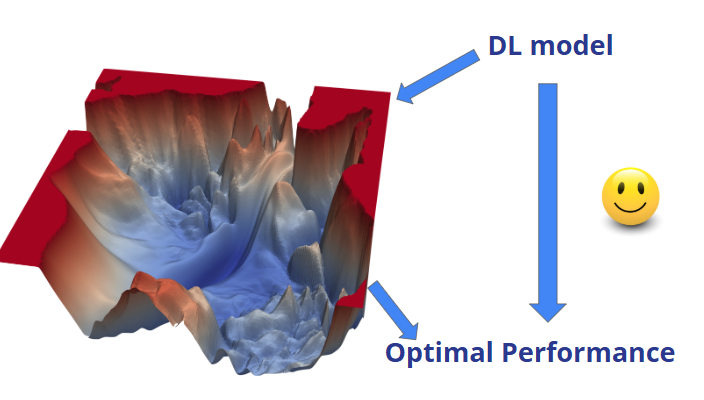




- Data manipulation
- Model Architectures and Ablations
- Hyperparameter Optimization
- Efficient Training and Logging

### Data manipulation

#### 1.1 Data Pre-processing


Audio Preprocessing for HW1P2

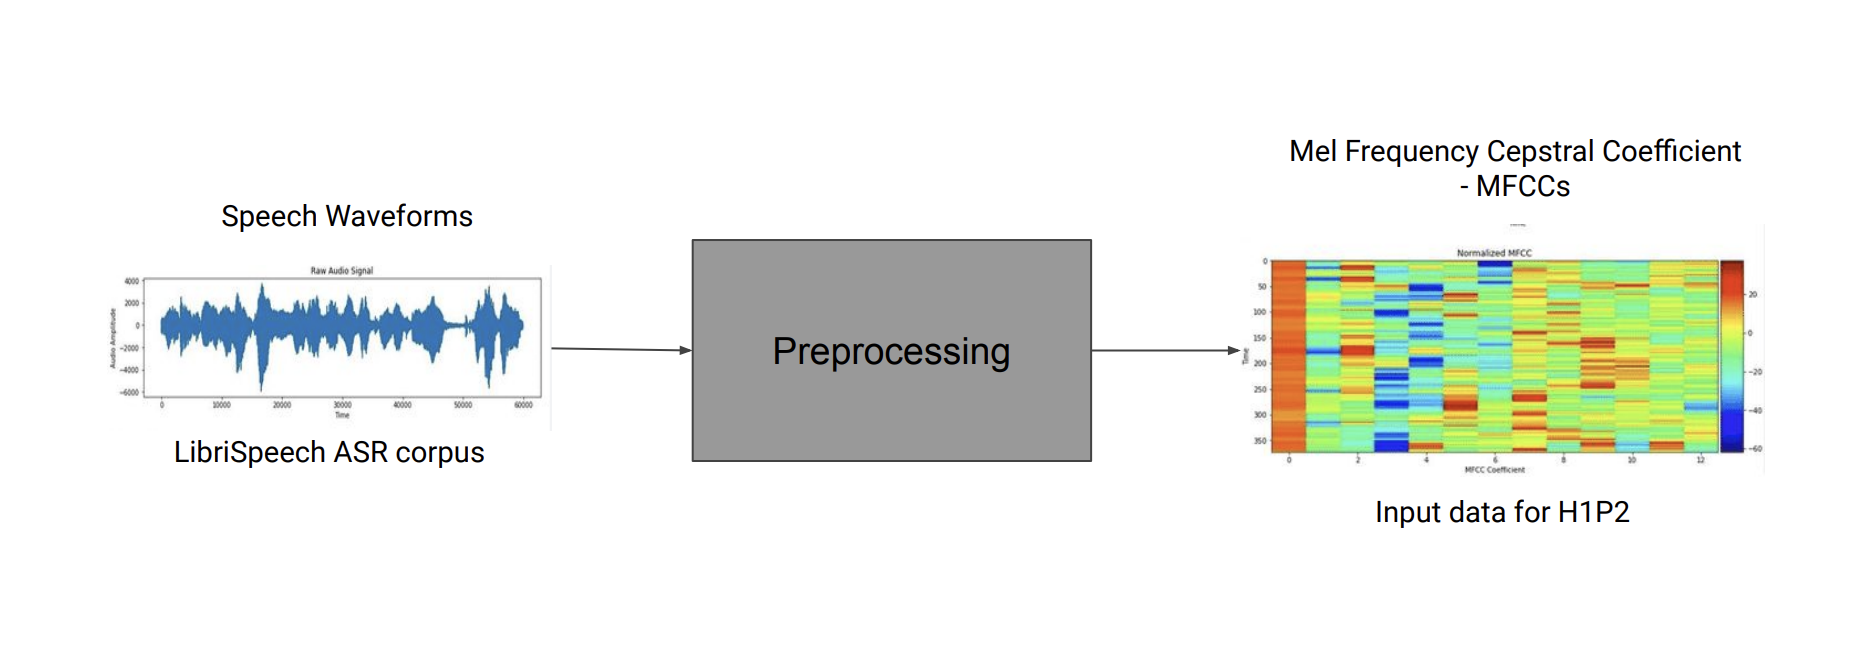

<!-- 2. Image preprocessing for HW2P2 -->




#### 1.2 Data Normalization

- Datasets obtained may have different scales for different features. In such cases, we scale the data which leads to faster convergence. It is also helpful when data is collected under varying conditions such as lighting in an image, gain in speech data, etc.

Types of normalization techniques:
- Z-score normalization (standardization)
- Min-max scaling
- Standard scaling
- Cepstral Mean Normalization


![](https://drive.google.com/uc?export=view&id=1ReitSqxpWBs8DRaiCStgh_CH98PN19yz)

##### Normalization in HW1P2 - Cepstral Mean Normalization

- Cepstral mean normalization (CMN) is a computationally efficient normalization technique for robust speech recognition.
- CMN minimizes distortion by noise contamination for robust feature extraction.
- CMN is used in different applications as this technique has proven to provide better speech recognitions results in different environments.
- CMN has the capabilities to reduce differences between test and training data produced by channel distortions.
- CMN can reduce differences in feature representation between speakers can also partly reduce the influence of background noise.

In [1]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google.colab'

In [ ]:
# Import libraries
!pip install gdown -q
import os
import torch
import torchvision
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import numpy as np
from PIL import Image

In [2]:
!pip install gdown==4.6.0

import gdown

file_id = "1pms9NiNlQhqzightGFHJ-LqN_RxhgWJk"
url = f"https://drive.google.com/uc?id={file_id}"
gdown.download(url, "image_data.zip", quiet=False)

!unzip image_data.zip
!rm image_data.zip

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Downloading...
From: https://drive.google.com/uc?id=1pms9NiNlQhqzightGFHJ-LqN_RxhgWJk
To: /Users/kouxiansheng/Downloads/CMU DP/lab/lab3/image_data.zip
100%|██████████| 22.7k/22.7k [00:00<00:00, 15.0MB/s]


Archive:  image_data.zip
replace image_data/dev_000002.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

OSError: [Errno 5] Input/output error

In [ ]:
DATA_DIR = "/content/image_data"
DEFAULT_CLASS_DIR = os.path.join(DATA_DIR, "default_class")

os.makedirs(DEFAULT_CLASS_DIR, exist_ok=True)

for filename in os.listdir(DATA_DIR):
    file_path = os.path.join(DATA_DIR, filename)
    if os.path.isfile(file_path):
        os.rename(file_path, os.path.join(DEFAULT_CLASS_DIR, filename))

dataset = ImageFolder(
    root=DATA_DIR,
    transform=transforms.Compose([
        transforms.ToTensor(),
    ])
)

##### Getting the mean of your dataset

In [ ]:
# Function to calculate mean and std of the dataset
def get_mean_and_std(loader):
    mean = 0.
    std = 0.
    total_images = 0
    for images, _ in loader:
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)
        mean += images.mean(2).sum(0)
        std += images.std(2).sum(0)
        total_images += batch_samples
    mean /= total_images
    std /= total_images
    return mean, std

##### Data visualization

In [3]:
# Calculate mean and std for normalization
data_loader = torch.utils.data.DataLoader(dataset=dataset, batch_size=3)
mean, std = get_mean_and_std(data_loader)
# Normalization and a form of augmentation to the dataset
# Define normalization transforms

#TODO Modify the values to see the effect on your dataset
normalize_transform = transforms.Compose([
                    transforms.Resize((256, 256)), # Ensures that the images are resized to 224x224
                    transforms.RandomHorizontalFlip(p=0.2), # Flips the image horizontally randomly with a probability of 50%
                    transforms.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.2), # Randomly changes the brightness, contrast, saturation, and hue
                    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)), # Random affine transformation of the image keeping center invariant
                    transforms.ToTensor(), # Converts the image to a PyTorch tensor
                    transforms.Normalize(mean=mean, std=std)
])

# Apply normalization to the dataset
dataset_norm = torchvision.datasets.ImageFolder(root=DATA_DIR, transform=normalize_transform )

dtl_norm = torch.utils.data.DataLoader(dataset=dataset_norm, batch_size=3)

# Display images with normalization
r, c = [2, 3]
fig, ax = plt.subplots(r, c, figsize=(15, 10))

# Display original images
dtl_pure = torch.utils.data.DataLoader(
    dataset=dataset,
    batch_size=3,
)
for data in dtl_pure:
    x, y = data
    for j in range(c):
        img = x[j].numpy().transpose(1, 2, 0)
        ax[0, j].imshow(img)
        ax[0, j].axis('off')
    break

# Display normalized images
for data in dtl_norm:
    x, y = data
    for j in range(c):
        img = x[j].numpy().transpose(1, 2, 0)
        img = (img * std.numpy() + mean.numpy()).clip(0, 1)  # Denormalize for visualization
        ax[1, j].imshow(img)
        ax[1, j].axis('off')
    break

ax[0, 0].set_title("Original Images")
ax[1, 0].set_title("Normalized Images")
plt.suptitle("Comparison of Images Before and After Normalization")
plt.show()

NameError: name 'torch' is not defined

#### 1.3 Data Augmentation

- Sometimes, it is not possible to obtain the amount of data required. In such cases, we can use data augmentation techniques to generate more data and it also makes the model more generalizable.

- You can use image augmentation techniques such as flipping, rotating, scaling, changing
perspective etc. and also Time masking and frequency masking for speech data used in all the HWs.

##### Data Augmentation in HW1P2 - Time and Frequency Masking

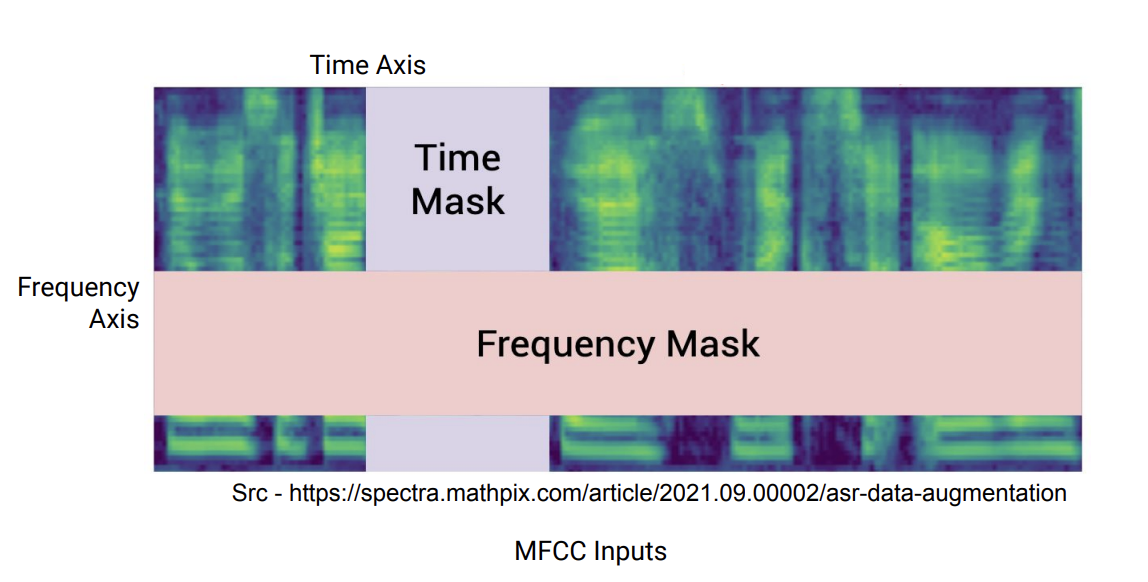

### 2. Ablations

* Keeping track of everything that would affect your model performance
* Model architecture
* Loss function,
* Optimizer
* Number of epochs

#### 2.1 Model Architecture

- As you might know already, one of your two biggest tasks in HW1P2 is to find the right model architecture for your MLP to be able to predict the phoneme of a given frame with context.
- Experimenting with finding the right model architecture is not easy - and takes a lot of time in a deep learning task.
- One of the ways to find useful architectures for your tasks is to to read papers, blogs, Piazza (for this course) and understand the intricacies and measure relative performance for your task.
- Typically, deeper and wider models tend to generally perform better (Why?) ?

##### 2.1.1 Model Architecture - Diamond

![](https://drive.google.com/uc?export=view&id=18_nbmDYBUhEgk1nZfoQoOHUUh7A4yU9o)

In [ ]:
class DiamondNetwork(torch.nn.Module):
    def __init__(self, input_size, output_size):
        super(DiamondNetwork, self).__init__()
        self.model = torch.nn.Sequential(
            # Input layer
            torch.nn.Linear(input_size, 100),
            torch.nn.BatchNorm1d(100),
            torch.nn.ReLU(),

            torch.nn.Linear(100, 200),
            torch.nn.BatchNorm1d(200),
            torch.nn.ReLU(),

            # Hidden layers (peak)
            torch.nn.Linear(200, 400),
            torch.nn.BatchNorm1d(400),
            torch.nn.ReLU(),

            torch.nn.Linear(400, 200),
            torch.nn.BatchNorm1d(200),
            torch.nn.ReLU(),

            torch.nn.Linear(200, 100),
            torch.nn.BatchNorm1d(100),
            torch.nn.ReLU(),

            # Output layer
            torch.nn.Linear(100, output_size)
        )

    def forward(self, x):
        return self.model(x)

input_size = 10
output_size = 2
model = DiamondNetwork(input_size, output_size)

##### 2.1.2 Model Architecture - Pyramid


![](https://drive.google.com/uc?export=view&id=1zDGLb6dnhv5DIbbrUChPNf3jTrZfKorm)

In [ ]:
# Checkpoint 1
class PyramidNetwork(torch.nn.Module):
    def __init__(self, input_size, output_size):
        super(PyramidNetwork, self).__init__()
        self.model = torch.nn.Sequential(
            # Input layer
            # TODO Complete the architecure
            torch.nn.Linear(input_size, 500),
            torch.nn.BatchNorm1d(500),
            torch.nn.ReLU(),

            # 第 2 块
            torch.nn.Linear(500, 400),
            torch.nn.BatchNorm1d(400),
            torch.nn.ReLU(),

            torch.nn.Linear(400, 300),
            torch.nn.BatchNorm1d(300),
            torch.nn.ReLU(),

            # 第 2 块
            torch.nn.Linear(300, 100),
            torch.nn.BatchNorm1d(100),
            torch.nn.ReLU(),
            # Output layer
            torch.nn.Linear(100, output_size)
        )

    def forward(self, x):
        return self.model(x)

##### 2.1.3 Model Architecture - Cylinder

![](https://drive.google.com/uc?export=view&id=1xvxiMZnYwEOXHV5S0kAy7oOWWXYRWdX_)

In [ ]:
# Checkpoint 2
class CylinderNetwork(torch.nn.Module):
    def __init__(self, input_size, output_size):
        super(CylinderNetwork, self).__init__()
        self.model = torch.nn.Sequential(
            # TODO complete this architecture
            # Input layer
            torch.nn.Linear(input_size, 200),
            torch.nn.BatchNorm1d(200),
            torch.nn.ReLU(),

            torch.nn.Linear(200, 200),
            torch.nn.BatchNorm1d(200),
            torch.nn.ReLU(),

            torch.nn.Linear(200, 200),
            torch.nn.BatchNorm1d(200),
            torch.nn.ReLU(),

            torch.nn.Linear(200, 200),
            torch.nn.BatchNorm1d(200),
            torch.nn.ReLU(),

            # Output layer
            torch.nn.Linear(200, output_size)
        )

    def forward(self, x):
        return self.model(x)

##### 2.1.4 Model Architecture - Hourglass

![](https://drive.google.com/uc?export=view&id=1PrNu1QnZjCpFoXZ7wG06jYcEhbk27bto)

In [ ]:
# Checkpoint 3
class HourglassNetwork(torch.nn.Module):
    def __init__(self, input_size, output_size):
        super(HourglassNetwork, self).__init__()
        self.model = torch.nn.Sequential(

            # Complete this architecture
            torch.nn.Linear(input_size, 500),
            torch.nn.BatchNorm1d(500),
            torch.nn.ReLU(),

            torch.nn.Linear(500, 300),
            torch.nn.BatchNorm1d(300),
            torch.nn.ReLU(),

            torch.nn.Linear(300, 100),
            torch.nn.BatchNorm1d(100),
            torch.nn.ReLU(),

            torch.nn.Linear(100, 200),
            torch.nn.BatchNorm1d(200),
            torch.nn.ReLU(),

            
            torch.nn.Linear(200, output_size)
        )

    def forward(self, x):
        return self.model(x)

### Tips

While working with MLPs in HW1P2, you will have to experiment with the following possibilities in your architecture,
- Network shape
- Deeper Layers
- Wider Layers
- Activation Functions (ReLU, Sigmoid, GELU, Softplus, Tanh)
- Batchnorm (more on this in an upcoming slide)
- Dropout (more on this in an upcoming slide)

Remember, you have a parameter limit so you have to construct your architecture around a limited budget of parameters. This will enable you to actively experiment with hyperparameters and
model structure than to just stick to models that are 10+ layers deep and over 8000 neurons wide at each layer and let it do its job.

### Loss landscape
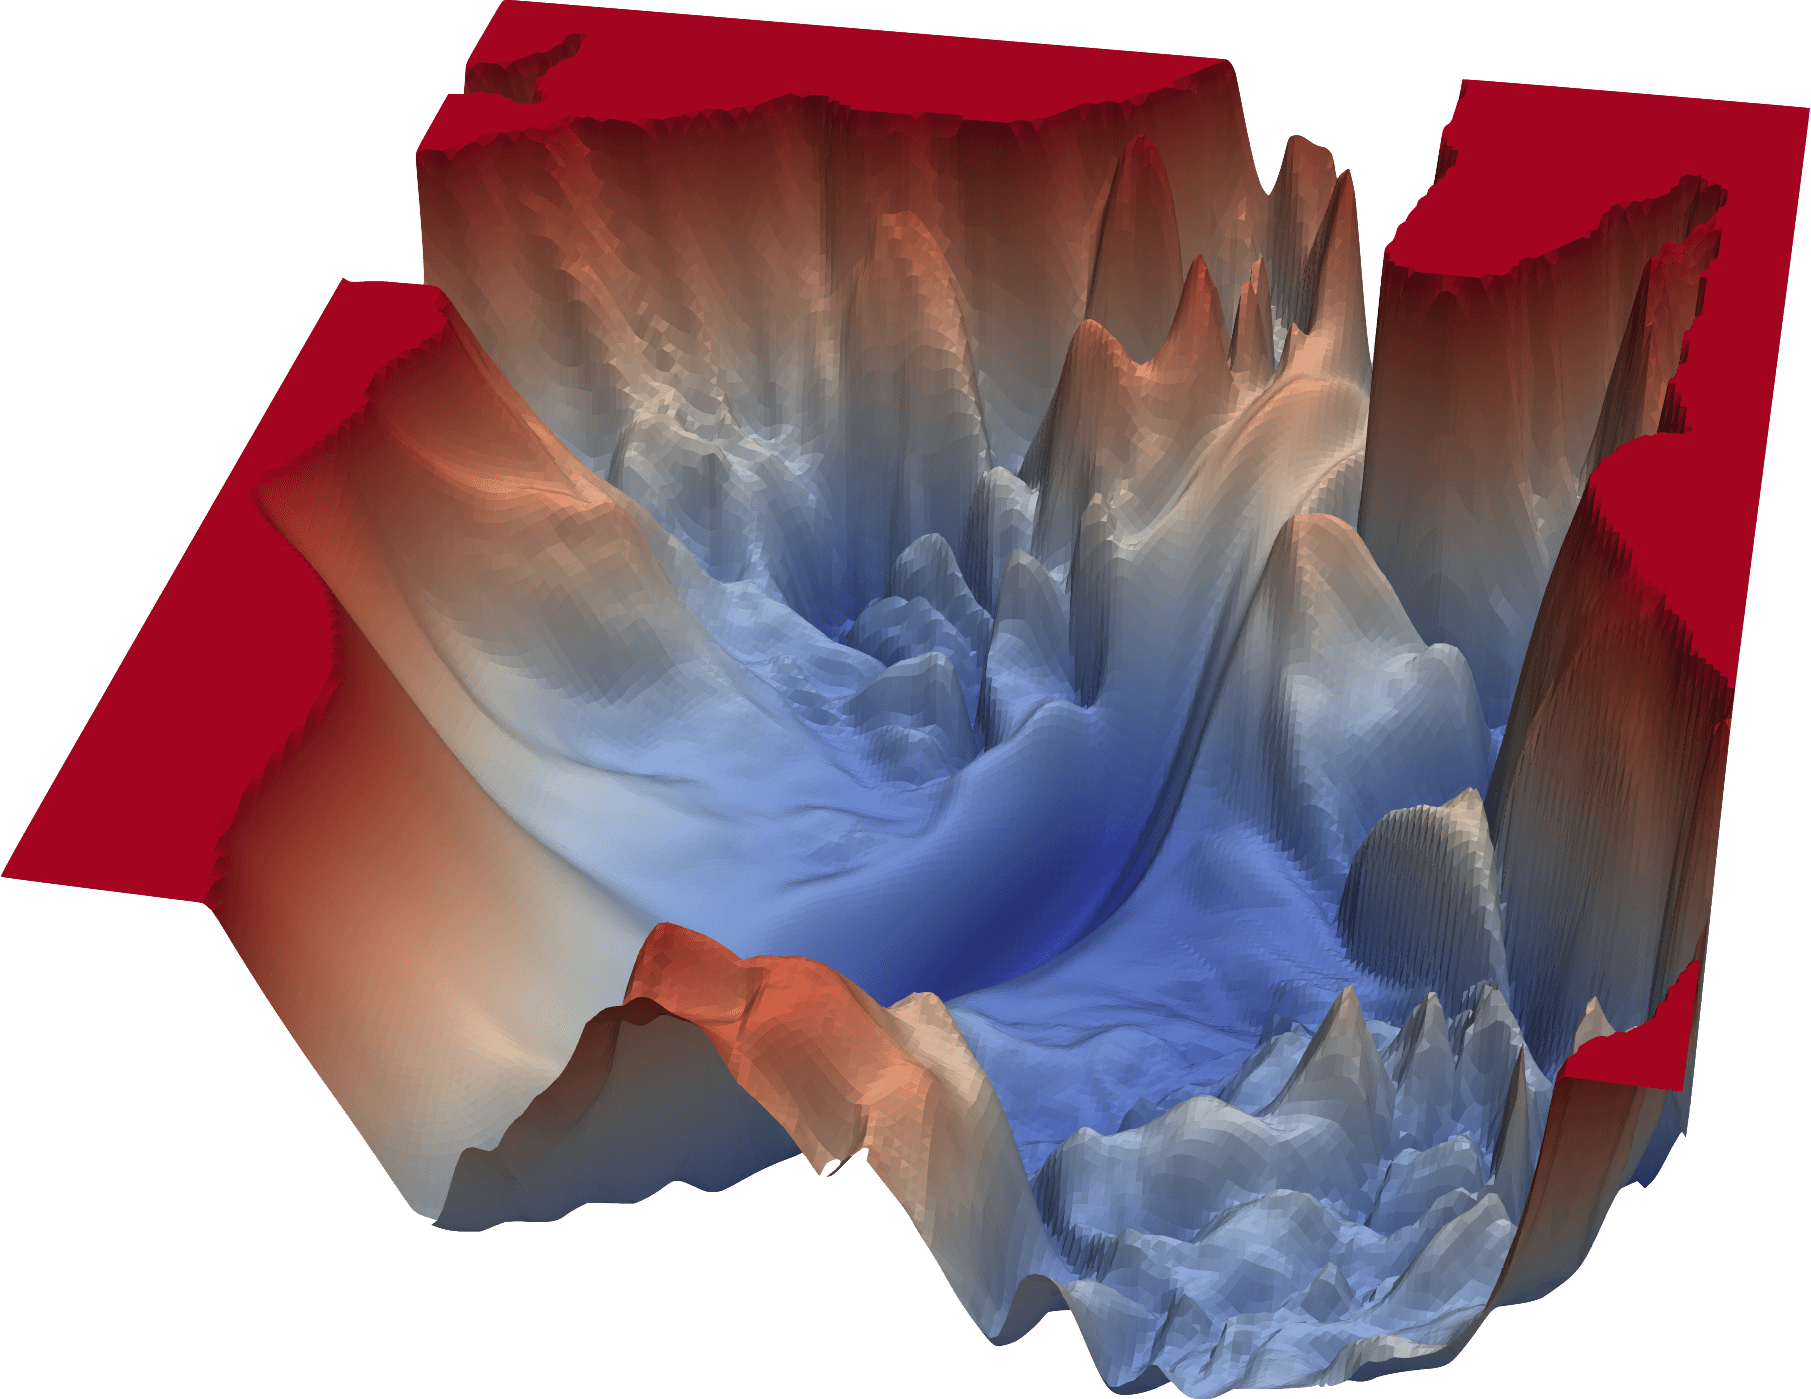




### 2.2 Schedulers and Learning Rate

##### 2.2.1 Learning Rate?

- LR is one of the most important hyperparameters while training models. It
controls the weight update step taken by your model during gradient descent, which directly influences convergence of your model for a deep learning task.

- You can experiment with different learning rates (also depends on the optimizer you select) as well as use a LR scheduler.


![](https://drive.google.com/uc?export=view&id=1k4aoB7y6wHq20anuvdM6Y3XdsUj2RdQq)


##### 2.2.2 What are Schedulers used for?
- The learning rate controls how big of a step for an optimizer to reach the minima of the loss function.
- A learning rate scheduler adjusts the learning rate according to a pre-defined schedule during the training process.

###### 2.2.2.1 Step LR

- The [StepLR](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.StepLR.html#torch.optim.lr_scheduler.StepLR) reduces the learning rate by a multiplicative factor after every predefined number of training steps.
- The LR scheduler effectively changes the LR across epochs based on a function or fixed schedule. You can also change the LR manually at certain epochs (but that may not be efficient in terms of resources spent monitoring training).

Reference for LR schedulers:
- https://pytorch.org/docs/stable/optim.html


![](https://drive.google.com/uc?export=view&id=1PGM73YtxXTsxd4Jcvtg1ESguKpottw1H)

In [ ]:
# Checkpoint 4

step_size = 4
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

# Define Scheduler for Learning Rate, including but not limited to StepLR, MultiStep, CosineAnnealing, CosineAnnealingWithWarmRestarts, ReduceLROnPlateau, etc.
# You can refer to Pytorch documentation for more information on how to use them.

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size, gamma=0.1, last_epoch=-1, verbose='deprecated')

###### 2.2.2.2 Multistep LR

The [MultiStepLR](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.MultiStepLR.html#torch.optim.lr_scheduler.MultiStepLR) — similarly to the [StepLR](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.StepLR.html#torch.optim.lr_scheduler.StepLR) — also reduces the learning rate by a
multiplicative factor but after each pre-defined milestone.

![](https://drive.google.com/uc?export=view&id=11tyesm8d8iQ_6WYhrXekCa_NH-Svhr6z)

In [ ]:
# Checkpoint 5

# MultiStepLR

# TODO: Complete this scheduler
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[30, 40, 45], gamma=0.5, last_epoch=-1, verbose='deprecated')

###### 2.2.2.3 Exponential LR

The [ExponentialLR](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ExponentialLR.html#torch.optim.lr_scheduler.ExponentialLR) reduces learning rate by a multiplicative factor at every training step.

![](https://drive.google.com/uc?export=view&id=1dp_atDsdN6h4vCXOfblTiqFPBrCSgm2n)

In [ ]:
# ExponentialLR
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma = 0.99, last_epoch=-1)

# What is the use of gamma?

###### 2.2.2.4 CosineAnnealing LR

- The [CosineAnnealingLR](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html#torch.optim.lr_scheduler.CosineAnnealingLR) reduces learning rate by a cosine function.
- While you could technically schedule the learning rate adjustments to follow
multiple periods, the idea is to decay the learning rate over half a period for the maximum number of iterations.

![](https://drive.google.com/uc?export=view&id=1zCzE7HFJp-7HO3W8QUby_0QOeE0WG5-P)

In [ ]:
# Checkpoint 6

# TODO complete the learning rate schedulers below
# Think about the function of T_max!

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50, eta_min=0, last_epoch=-1, verbose=False) # CosineAnnealing

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, eta_min=5e-6) # CosineAnnealing WarmRestart

# Think about the function of T_0!

###### 2.2.2.5 ReduceLRonPlateau

Reduce learning rate when a metric has stopped improving. This scheduler reads a metrics quantity and if no improvement is seen for a 'patience' number of epochs, the learning rate is reduced.
[ReaduceLROnPlateau](https://https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html)
![](https://drive.google.com/uc?export=view&id=1VkoQEHMNAV73bNUFHYfjNmUoQIm4kl8a)

In [ ]:
# Checkpoint 7
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=10, threshold=0.0001, threshold_mode='rel', cooldown=0, min_lr=0, eps=1e-08, verbose='deprecated')

# TODO
# How does changing the 'mode' affect your training?

### 2.3 Normalization Methods

Normalization standardizes and scales the input activations to have a consistent distribution, improving convergence and stability during training. It reduces internal covariate shift, mitigates vanishing/exploding gradients, and enhances generalization.

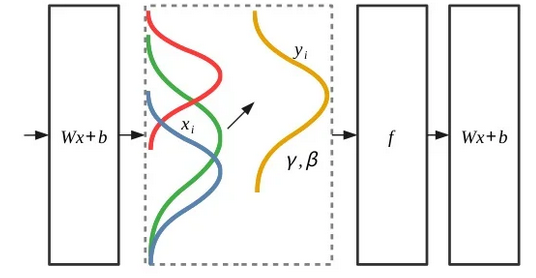

##### 2.3.1 Normalizations

- Batch Norm ([paper](https://arxiv.org/pdf/1502.03167))
  - Normalizes activations across the batch dimension to stabilize training, improve convergence, and reduce internal covariate shift. Introduces learnable scale and shift parameters.
- Layer Norm ([paper](https://arxiv.org/pdf/1607.06450))
  - Normalizes activations of neurons within a layer across feature dimensions within each individual sample, making it effective for NLP tasks.
- Group Norm ([paper](https://arxiv.org/pdf/1803.08494))
  - Divides channels into groups and normalizes within each group, maintaining performance consistency across small batch sizes.
- Instance Norm ([paper](https://arxiv.org/pdf/1607.08022))
  - Normalizes activations per sample across spatial dimensions, useful in tasks where batch-level statistics can be undesirable.
- Weight Norm ([paper](https://arxiv.org/pdf/1602.07868))
  - Reparameterizes weight vectors in a neural network by separating their magnitude and direction, leading to more stable training without batch dependencies.
- Batch-Instance Norm ([paper](https://arxiv.org/pdf/1805.07925))
  - Combines batch and instance normalization dynamically to adapt normalization strength.
- Switchable Norm ([paper](https://arxiv.org/pdf/1811.07727v1))
  - Learns to switch between different normalization techniques (Batch, Instance, Layer, Group) by optimizing a weighted combination of their statistics.

![](https://drive.google.com/uc?export=view&id=1otVyXWJ_dBr16Whe5R-aDM1F68d209oq)

##### 2.3.2 BatchNorm

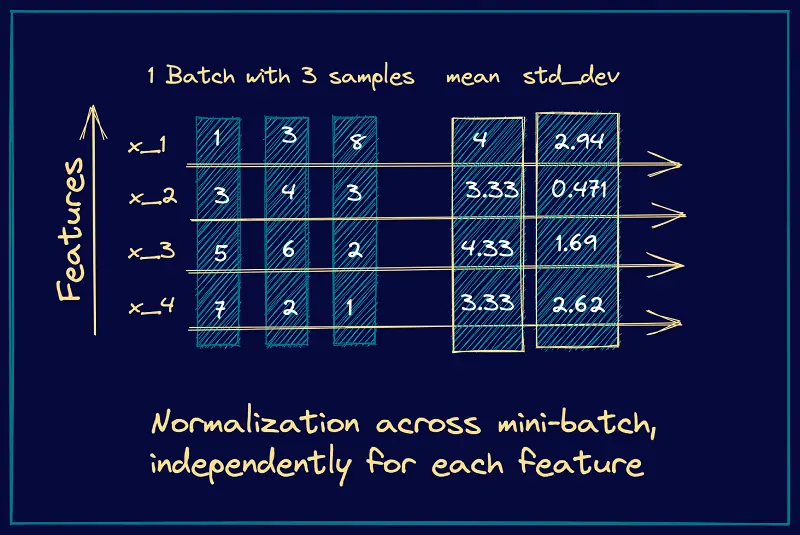

$$
\mu_{B,d}=\frac{1}{N}\sum_{i=1}^{N}x_{i,d},\qquad
\sigma_{B,d}^{2}=\frac{1}{N}\sum_{i=1}^{N}\left(x_{i,d}-\mu_{B,d}\right)^{2}
$$

$$
\hat{x}_{i,d}=\frac{x_{i,d}-\mu_{B,d}}{\sqrt{\sigma_{B,d}^{2}+\varepsilon}},\qquad
y_{i,d}=\gamma_d\,\hat{x}_{i,d}+\beta_d
$$

$$
\text{During Inference:}\qquad
\hat{x}_{i,d}=\frac{x_{i,d}-\mu_{\mathrm{run},d}}{\sqrt{\sigma_{\mathrm{run},d}^{2}+\varepsilon}},\qquad
y_{i,d}=\gamma_d\,\hat{x}_{i,d}+\beta_d
$$



$$
i \in \{1,\dots,N\}\ \text{indexes the batch (of size } N\text{), and }\ d \in \{1,\dots,D\}\ \text{indexes features.}
$$

$$
D\ \text{is the total number of features}
$$

$$
x_{i,d}\ \text{denotes the } d\text{-th feature (dimension) of the } i\text{-th example in the batch.}
$$



<img src="https://drive.google.com/uc?export=view&id=1iQy2K6RI1X9bjTQsI35Qqz8FO0NKEm7h" alt="batchnorm-code" width="300" height="400">

- Normalizing batch of inputs to eliminate internal covariate shift
- Applies Batch Normalization over a 2D or 3D input - `torch.nn.BatchNorm1d(num_features)`
- For 4D inputs (N,C,H,W) - `torch.nn.BatchNorm2d(num_features)`

<img src="https://drive.google.com/uc?export=view&id=1rNL6-sSpAOokLBmmot_r9TLcIS4kIn1a" alt="batchnorm-pros" width="700" height="350">

In [ ]:
def BatchNorm(x, gamma, beta, eps=1e-5):
    # x: input shape [N, C, H, W]
    # mean, var shape : [1, C, 1, 1]

    N, C, H, W = x.shape
    mean = torch.mean(input=x, dim=[0,2,3], keepdim=True)
    var = torch.var(input=x, dim=[0,2,3], keepdim=True)

    # Why normalize across [0,2,3]?
    # BatchNorm normalizes across the entire spatial map (H, W) per channel (C), ensuring that each feature map has zero mean and unit variance.

    # Normalize Input
    x = (x - mean) / torch.sqrt(var + eps)

    # gamma (γ) - Scale parameter
    # beta (β) - Shift parameter
    return x * gamma + beta

In [ ]:
# Checkpoint 8
import torch
import torch.nn as nn
import torch.nn.functional as F

class BatchNormModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(BatchNormModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)  # BatchNorm
        x = F.relu(x)         # Activation
        x = self.fc2(x)
        return x

##### 2.3.3 LayerNorm

**Problems with Batch Norm**
- Poor performance if the batch size is small, possible for high dimensional inputs.
- Running mean and variance might not be the best thing to calculate for sequential algorithms like RNNs.

Layer normalization calculates mean and variance for each item within the batch

Pytorch syntax - `torch.nn.LayerNorm(normalized_shape)`

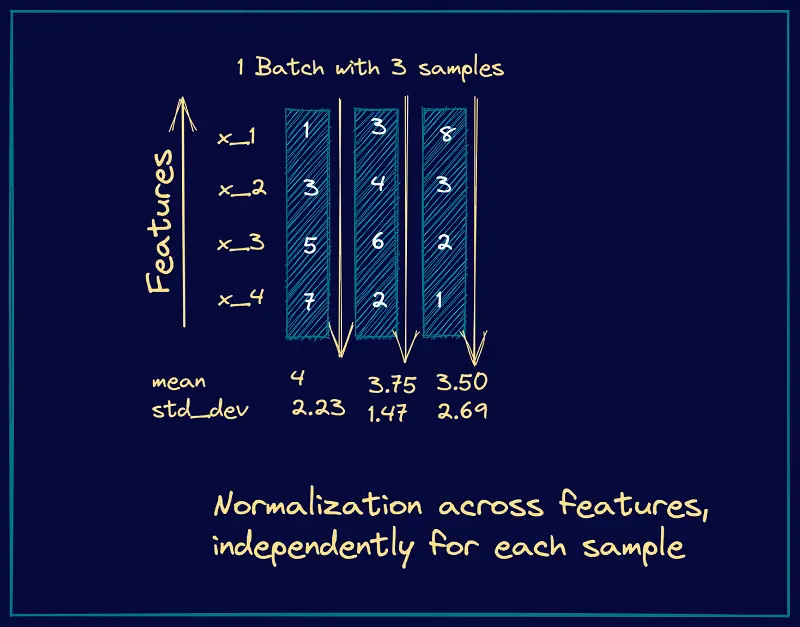

$$
\mu_i=\frac{1}{D}\sum_{d=1}^{D}x_{i,d},\qquad
\sigma_i^{2}=\frac{1}{D}\sum_{d=1}^{D}\left(x_{i,d}-\mu_i\right)^{2}
$$

$$
\hat{x}_{i,d}=\frac{x_{i,d}-\mu_i}{\sqrt{\sigma_i^{2}+\varepsilon}},\qquad
y_{i,d}=\gamma_d\,\hat{x}_{i,d}+\beta_d
$$

In [ ]:
def LayerNorm(x, gamma, beta, eps=1e-5):
    # x: input shape [N, C, H, W]

    N, C, H, W = x.shape
    mean = torch.mean(input=x, dim=[1,2,3], keepdim=True)
    var = torch.var(input=x, dim=[1,2,3], keepdim=True)
    # mean, var shape: [N, 1, 1, 1]

    x = (x - mean) / torch.sqrt(var + eps)

    return x * gamma + beta

In [ ]:
# Checkpoint 9
import torch
import torch.nn as nn
import torch.nn.functional as F

class LayerNormModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(LayerNormModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        # TODO: Add LayerNorm layer
        self.ln1 = nn.LayerNorm(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = self.ln1(x)  # LayerNorm
        x = F.relu(x)         # Activation
        x = self.fc2(x)
        return x

##### 2.3.4 GroupNorm

- Applies normalization over a mini-batch of inputs but splitted in groups of size num_channels/num_groups
- GN outperforms BN trained on smaller batches but can’t beat the larger batch results
- `torch.nn.GroupNorm(num_groups, num_channels)`

In [ ]:
def GroupNorm(x, gamma, beta, G, eps=1e-5):
    # x: input features with shape [N, C, H, W]
    # G : number of groups

    N, C, H, W = x.shape
    x = torch.reshape(input=x, shape=[N, G, C // G, H, W])
    mean = torch.mean(input=x, dim=[2,3,4], keepdim=True)
    var = torch.var(input=x, dim=[2,3,4], keepdim=True)
    # mean, var shape : [N, G, 1, 1, 1]

    x = (x - mean) / torch.sqrt(var + eps)

    x = torch.reshape(input=x, shape=[N, C, H, W])

    return x * gamma + beta

##### 2.3.5 InstanceNorm

- Calculates normalization parameters across individual channels/features for each input
- torch.nn.InstanceNorm1d(num_features)
- `torch.nn.InstanceNorm2d(num_features)`

In [ ]:
def InstanceNorm(x, gamma, beta, eps=1e-5):
    # x: input shape [N, C, H, W]

    N, C, H, W = x.shape
    mean = torch.mean(input=x, dim=[2,3], keepdim=True)
    var = torch.var(input=x, dim=[2,3], keepdim=True)
    # mean, var  shape: [N, C, 1, 1]

    x = (x - mean) / torch.sqrt(var + eps)

    return x * gamma + beta

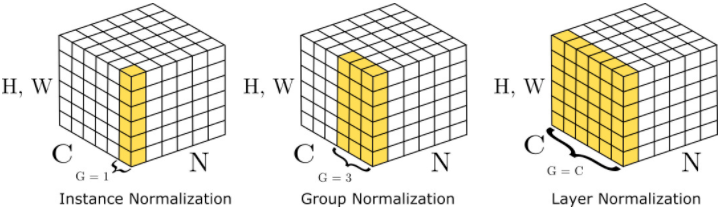

### 3. Hyperparameter Optimization

#### 3.1 Hyperparameter Information

##### 3.1.1 What are Hyperparameters?

- Explicitly speciﬁed parameters that control the training process

| Parameter  | Hyperparameter  |
|------------|---------------|
| Parameters are internal to the model - model weights, biases. | Hyperparameters are the explicitly specified parameters that control the training process. |
| Parameters are essential for making predictions. | Hyperparameters are essential for optimizing the model. |
| These are learned & set by the model by itself. | These are set manually by a machine learning engineer/practitioner. |

##### 3.1.2 Why do we need to tune hyperparameters?

- Improve Model Accuracy.
- Faster convergence for Model.
- Work with resource constraints (training time,  infrastructure, cost requirements etc.).
- Because I need to reach the HIGH cutoff. 😃

##### 3.1.3 Examples of Hyperparameters

- Batch Size
- Learning Rate
- Scheduler Parameters
- Dropout Probability
- Context
- Size of layers/number of layers
- Optimizer
- Weight Initialization


For Convolutional Neural Networks (HW2P2)
- Kernel size
- Stride


#### 3.2 Context

- Case 1: The case for longer context:
(1) Frames are short (20 to 40ms) and may not capture the whole sound
(2) You shall know a word  phoneme by the company it keeps. It is easier to predict what a phoneme is if you know what its neighbours are.
  - Why Longer Context is Good: It helps the model see a wider view of the audio signal, capturing patterns and dependencies between phonemes. Useful when phonemes are influenced by surrounding sounds or when the phoneme spans multiple frames.


- Case 2: The case for shorter context: MLPs are not well suited for sequences. The performance will degrade if the context is too high.
  - Another reason why context that's too long will not be useful here? When the context window is too large, it may introduce unnecessary noise or irrelevant information.
  - Why Shorter Context is Good: It helps in focusing on the most relevant frames, reducing the potential noise introduced by less influential frames.


- Solution:
Experiment with different context sizes



#### 3.3 Optimizer

- Gradient descent (iterative optimization algorithm based on a convex function that changes its parameters iteratively to minimize a given function to its local minimum) is the good way to optimize neural networks and other machine learning algorithms but is often used as a black box.

- How exactly do you train your model in practice? How do you change the parameters of your model, how much, and when?

- Enter optimizers. They tie together the loss function and model parameters by updating the model in response to the output of the loss function. Optimizers are mathematical functions which are dependent on model’s learnable parameters i.e Weights & Biases.
  - The loss function is the guide to the terrain, telling the optimizer when it's moving in the right or wrong direction.

- More formally, Optimizers are algorithms or methods used to change the attributes of your neural network such as weights and hyperparameters such as learning rate to minimize loss during training.

  - Examples of Optimizer Methods - Stochastic Gradient Descent (SGD), Adam (Adaptive Moment Estimation), AdamW, Sharpness Aware Minimization (SAM), Adagrad, RMSProp, etc.

  - Stochastic Gradient Descent (SGD) is one of the ﬁrst and most heavily used optimizers. But now, there are many other optimizers such as Nesterov Accelerated  Gradient (NAG), Adam, AdamW, Rmsprop, etc.

  - Generally, Adam converges faster in most cases  whereas SGD might converge slower but can ﬁnd a  better minima/generalize better.

- More theory on Optimizer Methods will be taught  in a lecture by the Professor in the near future :)

- There is a suggested approach of initially using Adam and then switching to SGD:  https://arxiv.org/abs/1712.07628.

<img src="https://drive.google.com/uc?export=view&id=1d_0ppugWmLjw511vCXyWFqE5Aa9-8qYe" alt="batchnorm-pros" width="600" height="400">




In [ ]:
# Checkpoint 10
import torch
import torch.nn as nn
import torch.optim as optim

model = nn.Linear(10, 1) # Dummy model
loss_fn = nn.MSELoss() # Dummy Loss
# TODO: Define an optimizer (e.g., Adam) with some learning rate
optimizer = optim.Adam(model.parameters(), lr=1e-3)

num_epochs = 2
for epoch in range(num_epochs):
    for _ in range(10):
        data = torch.randn(32, 10)
        target = torch.randn(32, 1)

        # TODO: Reset gradients with zero
        optimizer.zero_grad()
        output = model(data)
        loss = loss_fn(output, target)
        loss.backward()
        # TODO: Parameter update using step function
        optimizer.step()

In [ ]:
import torch
x = torch.tensor(2.0, requires_grad=True)

for step in range(4):
  # if x.grad is not None:
  #   x.grad.zero_() # Resets the gradient to 0
  y = x**2
  y.backward() # Then .backward() computes 4 and adds it to 0
  print(f"Step {step+1}: dy/dx (x.grad) = {x.grad.item()}")

Step 1: dy/dx (x.grad) = 4.0
Step 2: dy/dx (x.grad) = 8.0
Step 3: dy/dx (x.grad) = 12.0
Step 4: dy/dx (x.grad) = 16.0


#### 3.4 Weight Initialization

Why dont we initialize the weights with zeros or a constant or random values?

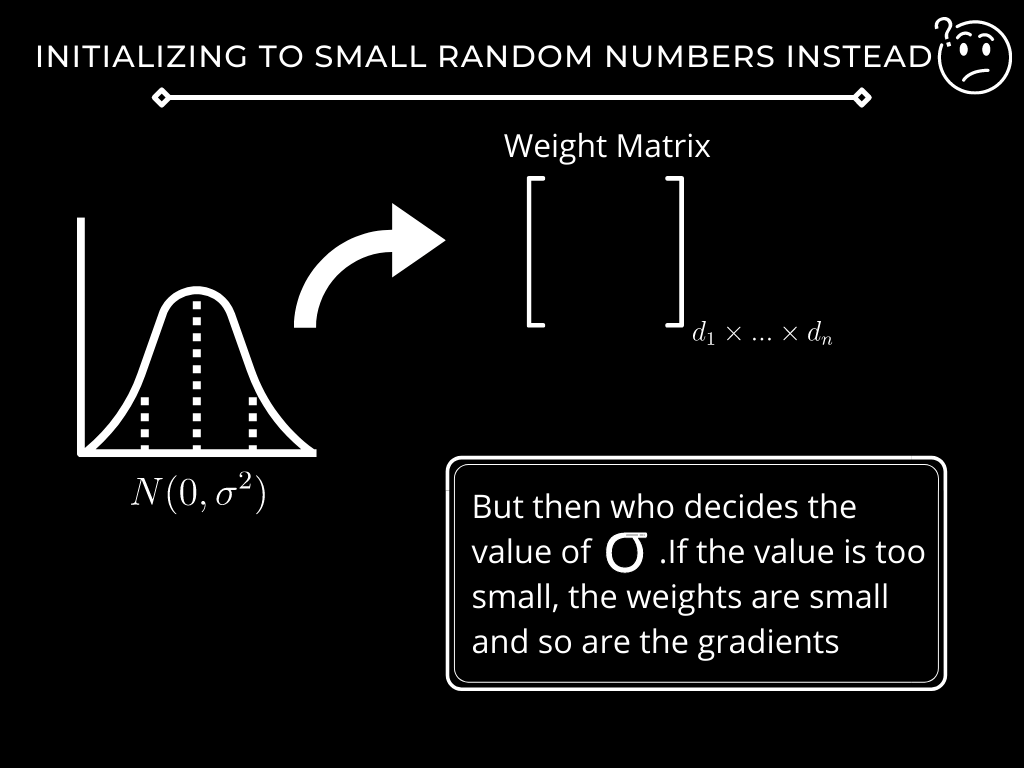

Goal: Activations should be spread out, not almost all the same value!

- Another facet to improve your performance is using weight initialization for your  hidden layers. This can result in faster convergence as well as ﬁnding better minima.

- There are a number of initializations you can try, ex. Xavier, Kaiming, Uniform, Gaussian, etc.  Depending on the type of activation function (ReLU, Sigmoid, etc.) and hidden layer  (linear, CNN, RNN, etc.) the initialization strategy would vary.

- Initializations also sometimes help resolve the issue of vanishing or exploding gradients.

- Note: PyTorch uses some initialization techniques for all of its layers, read them before  applying your own initialization strategies.


Ref:
- http://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf  
- https://arxiv.org/pdf/1502.01852.pdf  
- https://medium.com/@shoray.goel/kaiming-he-initialization-a8d9ed0b5899



<img src="https://drive.google.com/uc?export=view&id=1kAxwRQQ3Fge_JT8eJYTDemcBdM6HH9V6" alt="batchnorm-pros" width="700" height="300">

In [ ]:
# Checkpoint 12
import torch
import torch.nn as nn
import torch.nn.functional as F

class WeightInitModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(WeightInitModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)
        self._init_weights()

    def _init_weights(self):
        # TODO: Xavier Uniform initialization for fc1
        nn.init.xavier_uniform_(self.fc1.weight)
        nn.init.zeros_(self.fc1.bias)

        # TODO: Kaiming Uniform initialization for fc2
        nn.init.kaiming_uniform_(self.fc2.weight, nonlinearity='relu')
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x):
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        return x

#### 3.5 Overfitting and Underfitting

**Bias vs Variance:**
- Bias: Error that happens when a machine learning model is too simple and doesn't learn enough details from the data.
- Variance: Error that happens when a machine learning model learns too much from the data, including random noise.
- What is bias-variance tradeoff?


**Overfitting:**
- Overfitting happens when a model learns too much from the training data, including details that don't matter (like noise or outliers).
  - When the model memorizes the noise and ﬁts too closely to the training set, the model becomes  “overﬁtted,” and it is unable to generalize well to new data.
- High variance typically leads to overfitting, where the model performs well on training data but poorly on testing data  
- Fixes:
	- Improving the quality of training data reduces overfitting by focusing on meaningful patterns, mitigate the risk of fitting the noise or irrelevant features.
	- Increase the training data can improve the model's ability to generalize to unseen data and reduce the likelihood of overfitting.
	- Reduce model complexity.
	- Early stopping during the training phase.
	- Regularization Techniques.
	- Use dropout for neural networks to tackle overfitting.


**Underfitting:**
- Underfitting is the opposite of overfitting. It happens when a model is too simple to capture what's going on in the data.
- High bias typically leads to underfitting, where the model performs poorly on both train and test data because it fails to learn enough from the data.
- Fixes:
	- Increase model complexity.
	- Increase the number of features, performing feature engineering.
	- Remove noise from the data.
	- Increase the number of epochs or increase the duration of training to get better results.


<img src="https://drive.google.com/uc?export=view&id=1t3QrHpWiSKnmbZJIIelOvWlGdBY-cbdM" alt="batchnorm-pros" width="900" height="450">

#### 3.6 Dropout

- The term “dropout” refers to dropping out the  neurons (input and hidden layer) in a neural network.


- All the forward and backwards connections with a  dropped node are temporarily removed, thus  creating a new network architecture out of the  parent network.


- Different nodes are dropped by a dropout probability of 'p' during each forward pass.


- This leads to complex co-adaptations, which in turn reduces the overﬁtting problem because of which  the model generalises better on the unseen dataset.

<img src="https://drive.google.com/uc?export=view&id=1IWc4tYKpu3u8lNgDKKpGLFXPz1kw5krG" alt="batchnorm-pros" width="700" height="300">

In [ ]:
# Checkpoint 11
import torch
import torch.nn as nn
import torch.nn.functional as F

class DropoutModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout_p=0.5):
        super(DropoutModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        # TODO: Add a dropout layer with probability = dropout_p
        self.dropout = nn.Dropout(dropout_p)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = F.relu(x)         # Activation
        x = self.dropout(x)  # Apply dropout
        x = self.fc2(x)
        return x

#### 3.7 Other Techniques

##### 3.7.1 Early Stopping

Literally, just stop the training when you see the validation score decreasing,  where overﬁtting is likely to begin.

<img src="https://drive.google.com/uc?export=view&id=13wbdfC728lV06wr0DNTetDm515s35jPi" alt="batchnorm-pros" width="700" height="400">

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

model = nn.Linear(10, 1)
optimizer = optim.SGD(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

def train_one_epoch(model, optimizer):
    data   = torch.randn(32, 10)
    target = torch.randn(32, 1)
    optimizer.zero_grad()
    output = model(data)
    loss   = criterion(output, target)
    loss.backward()
    optimizer.step()

def validate(model):
    val_loss = np.random.random()
    return val_loss

num_epochs = 10
best_val_loss = np.inf
patience = 2
counter = 0

for epoch in range(num_epochs):
    train_one_epoch(model, optimizer)
    val_loss = validate(model)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        torch.save(model.state_dict(), 'best_model.pt')
        print(f"Epoch {epoch}: New best val_loss = {val_loss:.4f}. Model saved.")
    else:
        counter += 1
        print(f"Epoch {epoch}: val_loss = {val_loss:.4f}. No improvement.")

        # Trigger early stopping if no improvement for 'patience' epochs
        if counter >= patience:
            print("Early stopping triggered!")
            state_dict = torch.load('best_model.pt', weights_only=True)
            model.load_state_dict(state_dict)
            break

Epoch 0: New best val_loss = 0.3204. Model saved.
Epoch 1: New best val_loss = 0.1180. Model saved.
Epoch 2: val_loss = 0.4049. No improvement.
Epoch 3: val_loss = 0.8050. No improvement.
Early stopping triggered!


##### 3.7.2 Gradient Clipping

Once the gradient is over the threshold, clip  and keep them to the threshold value. This  helps avoid exploding gradients, especially  useful in recurrent networks as you will see later in the course.

Ref:
- https://neptune.ai/blog/understanding-gradient-clipping-and-how-it-can-fix-exploding-gradients-problem

<img src="https://drive.google.com/uc?export=view&id=1RhisszcmU2rD4tct2bgR2l7tkqZa5amu" alt="batchnorm-pros" width="700" height="300">


In [ ]:
# Checkpoint 13
import torch
import torch.nn as nn
import torch.optim as optim

model = nn.Linear(10, 1)
loss_fn = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=1e-3)

num_epochs = 2
max_norm = 1.0

for epoch in range(num_epochs):
    for _ in range(10):
        data = torch.randn(32, 10)
        target = torch.randn(32, 1)

        optimizer.zero_grad()
        output = model(data)
        loss = loss_fn(output, target)
        loss.backward()

        # TODO: Clip the gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)

        optimizer.step()

3.7.3 Regularization

Sometimes weights grow to very large magnitudes during training. So we need to avoid this.

$$
\min_{W,b}\; \mathcal{L}(W,b;\mathcal{D}) + \frac{\lambda}{2}\|W\|_2^2
$$

In PyTorch, you set regularization constant (lambda) through weight decay argument as follows:

`optimizer = optim.Adam(model.parameters() , lr=0.001, weight_decay=0.1)`

Regularization also prevents overfitting

### 4. Homework Part 2s Tips

#### 4.1 Mixed Precision Training

- Mixed Precision Training (Pytorch > 1.6.0)
  - combine FP32 (accurate but memory-intensive/computationally expensive) and FP16 (faster, less memory intensive but can lead to precision loss and overflow/underflow issues) during training while achieving same accuracy as FP32 training
  - AMP selects which operations can be safely done in FP16 and which need to remain in FP32
  - GradScaler prevent underflow issues like small gradients getting rounded to zero


- Why use Mixed Precision?
  - faster training (2-3x)
  - less memory usage
  - larger batch size, larger model, larger input

- How? What about loss of information?
  - We keep a master copy of weights in FP32.
  - This is converted into FP16 during part of each  training iteration (one forward pass, back-propagation and weight update).
  - At the end of the iteration, the weight gradients  are converted back to FP32 and used to update  the master weights during the optimizer step.


<img src="https://drive.google.com/uc?export=view&id=1fJhg6Fi0B3BLJTzX5B0G47m-349_nVfT" alt="batchnorm-pros" width="700" height="600">

Read:
- https://pytorch.org/docs/stable/notes/amp_examples.html

Note:
- Mixed Precision Training  works only for some GPUs,  including Tesla T4, V100 and  A100 GPUs. It does not work  with a P100 GPU.


Read the link and understand the concepts like gradient clipping (for the exploding gradient problem), gradient accumulation (larger effective batch size without the memory overhead), and gradient penalty (constrained optimization eg L2 penalty to prevent large parameters)


<img src="https://drive.google.com/uc?export=view&id=1UjS0aTmkkF4ciyQt3Kj67hNJJWx4BWEP" alt="batchnorm-pros" width="700" height="500">

#### 4.2 Keep in Mind

- DO NOT spend time exploring all possible architectural and hyperparameter variations yourself. This is  where you make use of the course collaboration policy to take help of your study group to divide and  conquer your HW ablation studies.

- Spend some time discussing possible variations together and divide it among each other, and log your  experiments in your wandb team. Divide and Conquer is the way to succeed in HWs in this course.

- Spending time on a portion/sample of the dataset initially might help you make choices quicker on what  works and doesn't work. This can be very useful when exploring wildly different strategies at the  beginning, and then ﬁltering out variants that work and training them on the full dataset to eliminate  further nuanced variations in the subset of architectures and hyperparameters.

- A huge portion of your time might go into just monitoring your training on Colab/AWS and being  anxious about your architecture's performance.

- We recommend starting early for this very reason so that you don't have to worry about wasting too  much time on architecture search to see what works well and doesn't in the last minute, forcing you  to keep your eyes glued to training and wasting time doing nothing else.

- You will be provided with the medium cutoff architecture soon, look out for a post on Piazza  regarding it in the coming week, and use it as a ﬁrst step to ensure you get 70 points.



#### 4.3 Study Groups

<img src="https://drive.google.com/uc?export=view&id=1vEcmzFyW1q-bntHvDD-ogtXMKeiTsliQ" alt="batchnorm-pros" width="850" height="500">

#### 4.4 Wandb

- You might already be familiar with weights and biases at this point, given we have provided you code to  work with in the starter notebook for HW1P2. It is simple code to get you started, but you can do so much  more with weights and biases such as hyperparameter sweeps. Please refer to Recitation 0, to learn more  about Wandb. We highly recommend using it, at least for logging metrics at the minimum.

- If you haven't already - Use weights and biases as given in the starter notebook to log your experiments.

- Create a team in weights and biases and ask your study group members to join it, so that you can share  ablation results with each other as you are conducting experiments as a group. This reduces anxiety in  your architecture/hyperparameter search by a LOT and we highly recommend doing this.

<img src="https://drive.google.com/uc?export=view&id=19XIGJT4hMp8Da66V_0r6lu4B-Sqcpx3Y" alt="batchnorm-pros" width="850" height="450">

##### 4.4.1 Wandb Version Control and Artifacts

- Save Model Checkpoints, conﬁgs, architecture
- Access it from anywhere
- Resume logging from previous runs

<img src="https://drive.google.com/uc?export=view&id=1nh_0SS6BYBWkc8ON7P5d_7C3X4n9TEg-" alt="batchnorm-pros" width="750" height="300">

<img src="https://drive.google.com/uc?export=view&id=15cTwa_bfbW726uGRgDz5sWNX0cZrPmko" alt="batchnorm-pros" width="750" height="300">

##### 4.4.2 Wandb Sweep

- Covered in Recitation 0

- Insights from sweep:  
  - https://wandb.ai/11785-sg/CIFAR-Sweep/sweeps/5h4vbyqk

- Can automate the hyperparameter search process by defining a range of hyperparameters, WandB orchestrates the execution of multiple experiments

- Warning: Time consuming and might be hard to interpret the hyperparameters that were responsible for performance improvements.

- How to address:
  - Limit the search space and refine.
  - Use early stopping.
  - Try different hyperparameter distributions.

- Strategies:
  - Run smaller exploratory sweep in the beginning to find a basic baseline.
  - Run focused swerrp to fine-tune, once you have a well-performing architecture with a smaller search space.
  - Do both. (Use Study Group)

<img src="https://drive.google.com/uc?export=view&id=1vdoND-A5jEOwypNvCGhEDShgpy3EwG6W" alt="batchnorm-pros" width="800" height="650">

#### 4.5 HW1P2 Hints

- Always keep this in mind: **Practice maketh a man perfect**! Besides the theory behind different  algorithms and different tricks, Deep Learning is kind like an experimental topic. If you wonder what  tricks can achieve best results or which parameters suit the model well, just give it try!

- Remember to shufﬂe the training data set. Note: **Do not shufﬂe the test or validation set**.

- **Choose learning rate wisely**: too large LR will result in the model taking huge steps in weight updates  and diverging/not converging while too small can hardly get rid of local optima.

- Choose batch size: according to the property of SGD, smaller batch size leads to better convergence  rate. But smaller batch size would deteriorate the performance of BatchNorm layer and running  speed. In general, different batch size wouldn't cause too much difference. Larger batch size tends to  have better performance but will occupy more memory in GPU.

- Explore ensembling - some examples are (more on this will be explained in a future lecture and recitation)
  - Training multiple models and taking a majority vote during classiﬁcation
  - Self-ensemble: average the parameters of your model at different training epochs.
  - Remember, you are however limited to 20 million parameters in total for your ﬁnal overall network.


- **Don't forget optimize.zero_grad()** while training, and **torch.inference_mode()** while evaluating.


- Experiment with LR schedulers, they are very crucial in improving model performance - CosineAnnealing,  ExponentialLR, StepLR, MultiStepLR, ReduceLROnPlateau, etc are some examples to explore.
  - Learning rate must shrink with time for convergence!


- Try to use **torch.cuda.empty_cache()** and del to release all unoccupied cached memory.

- DataLoader has bad default settings, so remember to tune **num_workers > 0 and default to pin_memory = True** (Colab will gradually restrict the num_workers from 8 to 4 to 2 and then only 1, unfortunately	)

- If you are getting CUDA related errors, switch your code to CPU and run it - more often than not, it will give you a better error output and point you towards what is wrong/buggy with your code.

- Setting bias = False in weight layers before BatchNorms might be useful, as each BatchNorm layer will re-center the data anyway, removing the bias and making it a useless trainable parameter.

- Try possible tricks or models that you can ﬁnd in the papers or posts online!

- Remember to checkpoint your model after each epoch!


<img src="https://drive.google.com/uc?export=view&id=18iioioNnvKpuEH5Ue7MADwU1PyI_GUPZ" alt="batchnorm-pros" width="700" height="450">